# GLoRIA on combined dataset (CheXpert + VinDr-CXR)

In [1]:
# Import libraries and set the experiment configuration
import importlib.util
import io
import json
import subprocess
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    precision_recall_curve, precision_recall_fscore_support,
    roc_auc_score, roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms

SEED = 42
MAX_EPOCHS = 50
PATIENCE = 10
IMAGE_BATCH_SIZE = 64
HEAD_BATCH_SIZE = 64
NUM_WORKERS = 4
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
KEYS = ['atelectasis', 'cardiomegaly', 'consolidation', 'pleural_effusion']
TARGETS = ['target_' + key for key in KEYS]
MASKS = ['mask_' + key for key in KEYS]

INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
RESULTS = WORK / 'gloria_combined_chexpert_vindr_results'
RESULTS.mkdir(parents=True, exist_ok=True)
run_start = time.perf_counter()

if not torch.cuda.is_available() or torch.cuda.device_count() < 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Notebook settings.')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('Using:', torch.cuda.get_device_name(0), 'and', torch.cuda.get_device_name(1))


Using: Tesla T4 and Tesla T4


In [2]:
# Find the combined ZIP and GLoRIA checkpoint, then clone the authors' code
ZIP_PATH = ''
CHECKPOINT_PATH = ''
zip_matches = [Path(ZIP_PATH)] if ZIP_PATH else list(INPUT.rglob('chexpert_vindr_combined.zip'))
checkpoint_matches = [Path(CHECKPOINT_PATH)] if CHECKPOINT_PATH else list(INPUT.rglob('chexpert_resnet50.ckpt'))
if len(zip_matches) != 1 or not zip_matches[0].is_file():
    raise FileNotFoundError('Attach one chexpert_vindr_combined.zip notebook output, or set ZIP_PATH.')
if len(checkpoint_matches) != 1 or not checkpoint_matches[0].is_file():
    raise FileNotFoundError('Attach one GLoRIA chexpert_resnet50.ckpt input, or set CHECKPOINT_PATH.')
archive_path = zip_matches[0]
checkpoint_path = checkpoint_matches[0]
if not zipfile.is_zipfile(archive_path):
    raise ValueError(f'Invalid combined ZIP: {archive_path}')

repo = WORK / 'gloria_official'
if not (repo / 'gloria/models/cnn_backbones.py').is_file():
    subprocess.run(
        ['git', 'clone', '--depth', '1', 'https://github.com/marshuang80/gloria.git', str(repo)],
        check=True,
    )
repo_commit = subprocess.check_output(
    ['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True,
).strip()
print('Combined ZIP:', archive_path)
print('GLoRIA checkpoint:', checkpoint_path)
print('GLoRIA source:', repo_commit)


Cloning into '/kaggle/working/gloria_official'...


Combined ZIP: /kaggle/input/notebooks/shadril238/chexpert-vindr-combined-image-dataset/chexpert_vindr_combined.zip
GLoRIA checkpoint: /kaggle/input/datasets/shadril238/gloria-chexpert-checkpoint/chexpert_resnet50.ckpt
GLoRIA source: 416466af1036294301a872e4da169fefc137a192


In [3]:
# Read the packaged splits and verify the shared labels and image paths
with zipfile.ZipFile(archive_path) as archive:
    names = set(archive.namelist())
    test_manifests = sorted(name for name in names if name.endswith('test/labels.csv'))
    if len(test_manifests) != 1:
        raise FileNotFoundError(f'Expected one test/labels.csv in the combined ZIP; found {len(test_manifests)}.')
    archive_prefix = test_manifests[0][:-len('test/labels.csv')]
    settings_files = sorted(name for name in names if name.endswith('settings.json'))
    if archive_prefix + 'settings.json' in names:
        settings_path = archive_prefix + 'settings.json'
    elif len(settings_files) == 1:
        settings_path = settings_files[0]
    else:
        settings_path = None
    settings = json.loads(archive.read(settings_path)) if settings_path else None
    if settings is not None and (
        settings.get('labels') != LABELS or
        settings.get('targets') != TARGETS or
        settings.get('masks') != MASKS
    ):
        raise ValueError('The attached combined ZIP settings do not match the four expected findings.')
    splits = {}
    for name in ['train', 'validation', 'test']:
        csv_path = archive_prefix + name + '/labels.csv'
        if csv_path not in names:
            raise FileNotFoundError(f'Missing {csv_path} in the combined ZIP.')
        frame = pd.read_csv(archive.open(csv_path))
        required = {'sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS}
        if not required.issubset(frame.columns):
            raise ValueError(f'{name} labels are missing {sorted(required - set(frame.columns))}.')
        if frame.empty or frame['sample_id'].isna().any() or frame['sample_id'].duplicated().any():
            raise ValueError(f'{name} contains no rows, missing IDs, or repeated IDs.')
        frame['zip_image_path'] = frame['image_path'].map(
            lambda value: str(value) if str(value) in names else archive_prefix + str(value).lstrip('/'))
        missing = set(frame['zip_image_path']) - names
        if missing:
            raise FileNotFoundError(f'{name}: {len(missing)} packaged images are missing; example: {next(iter(missing))}')
        for column in TARGETS + MASKS:
            frame[column] = pd.to_numeric(frame[column], errors='raise')
            if frame[column].isna().any() or not frame[column].isin([0, 1]).all():
                raise ValueError(f'{name}/{column} must contain only 0 and 1.')
            frame[column] = frame[column].astype(np.uint8)
        if set(frame['source_dataset']) != {'chexpert', 'vindr'}:
            raise ValueError(f'{name} must contain CheXpert and VinDr images.')
        splits[name] = frame.reset_index(drop=True)

for field in ['sample_id', 'group_id', 'zip_image_path']:
    values = [set(frame[field]) for frame in splits.values()]
    if values[0] & values[1] or values[0] & values[2] or values[1] & values[2]:
        raise ValueError(f'{field} overlaps across splits.')
train_df, val_df, test_df = (splits[name] for name in ['train', 'validation', 'test'])
if settings is None:
    print('ZIP settings.json absent; verified labels, masks, splits, and images from the CSV files.')
for name, frame in splits.items():
    print(f'{name}: {len(frame):,} images | ' +
          ', '.join(f'{source} {count:,}' for source, count in frame.source_dataset.value_counts().items()))


ZIP settings.json absent; verified labels, masks, splits, and images from the CSV files.
train: 19,973 images | vindr 12,000, chexpert 7,973
validation: 2,526 images | vindr 1,500, chexpert 1,026
test: 2,501 images | vindr 1,500, chexpert 1,001


In [4]:
# Prepare the same normalized 256-to-224 image input as the CheXpert notebook
transform = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

class CombinedImages(Dataset):
    def __init__(self, frame, path):
        self.paths = frame['zip_image_path'].tolist()
        self.archive_path = str(path)
        self.archive = None

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        if self.archive is None:
            self.archive = zipfile.ZipFile(self.archive_path)
        with self.archive.open(self.paths[index]) as source:
            image_bytes = source.read()
        with Image.open(io.BytesIO(image_bytes)) as image:
            image = ImageOps.pad(
                image.convert('L'), (256, 256),
                method=Image.Resampling.BILINEAR, color=0,
            ).convert('RGB')
            return transform(image)

def image_loader(frame):
    return DataLoader(
        CombinedImages(frame, archive_path), batch_size=IMAGE_BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,
    )

print('ZIP image loader ready.')


ZIP image loader ready.


In [5]:
# Load the same released GLoRIA ResNet-50 image encoder used for CheXpert
source = repo / 'gloria/models/cnn_backbones.py'
spec = importlib.util.spec_from_file_location('gloria_backbones', source)
official = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official)
backbone, feature_size, _ = official.resnet_50(pretrained=False)

weights_file = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
checkpoint_weights = weights_file.get('state_dict', weights_file)
model_weights = backbone.state_dict()
weights = {}
for name, value in checkpoint_weights.items():
    marker = 'img_encoder.model.'
    if marker in name:
        key = name.split(marker, 1)[1]
        if key in model_weights and value.shape == model_weights[key].shape:
            weights[key] = value
if len(weights) < 250:
    raise ValueError('The attached checkpoint is not the released GLoRIA ResNet-50 checkpoint.')
backbone.load_state_dict(weights, strict=True)
del weights_file, checkpoint_weights, model_weights, weights
backbone.eval()

class GLoRIAFeatures(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, images):
        images = nn.functional.interpolate(
            images, size=(299, 299), mode='bilinear', align_corners=True,
        )
        return self.model(images)

encoder = nn.DataParallel(GLoRIAFeatures(backbone), device_ids=[0, 1]).cuda().eval()
print('Loaded GLoRIA image encoder with', feature_size, 'features per image.')


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loaded GLoRIA image encoder with 2048 features per image.


In [6]:
# Extract a frozen GLoRIA feature vector for every image once
def extract_features(frame, split_name):
    vectors = np.empty((len(frame), feature_size), dtype=np.float16)
    offset = 0
    with torch.inference_mode():
        for images in image_loader(frame):
            with torch.autocast('cuda', dtype=torch.float16):
                batch = encoder(images.cuda(non_blocking=True))
            count = len(batch)
            if batch.ndim != 2 or batch.shape[1] != feature_size or not torch.isfinite(batch).all():
                raise ValueError(f'Invalid GLoRIA features in {split_name} at image {offset}.')
            vectors[offset:offset + count] = batch.cpu().numpy().astype(np.float16)
            offset += count
            if offset % 5000 < count or offset == len(frame):
                print(f'{split_name}: {offset:,}/{len(frame):,} images', flush=True)
    if offset != len(frame):
        raise ValueError(f'{split_name} feature count does not match its manifest.')
    return vectors

feature_start = time.perf_counter()
train_x = extract_features(train_df, 'train')
val_x = extract_features(val_df, 'validation')
test_x = extract_features(test_df, 'test')
feature_minutes = (time.perf_counter() - feature_start) / 60
train_y = train_df[TARGETS].to_numpy(dtype=np.float32)
val_y = val_df[TARGETS].to_numpy(dtype=np.float32)
test_y = test_df[TARGETS].to_numpy(dtype=np.float32)
train_mask = train_df[MASKS].to_numpy(dtype=np.float32)
val_mask = val_df[MASKS].to_numpy(dtype=np.float32)
test_mask = test_df[MASKS].to_numpy(dtype=np.float32)
print(f'Feature extraction finished in {feature_minutes:.1f} minutes.')


train: 5,056/19,973 images
train: 10,048/19,973 images
train: 15,040/19,973 images
train: 19,973/19,973 images
validation: 2,526/2,526 images
test: 2,501/2,501 images
Feature extraction finished in 1.1 minutes.


In [7]:
# Train a four-label linear head with masked BCE and validation early stopping
def head_loader(features, labels, masks, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(features.astype(np.float32)),
        torch.from_numpy(labels),
        torch.from_numpy(masks),
    )
    return DataLoader(dataset, batch_size=HEAD_BATCH_SIZE, shuffle=shuffle)

train_loader = head_loader(train_x, train_y, train_mask, shuffle=True)
val_loader = head_loader(val_x, val_y, val_mask)
head = nn.Linear(feature_size, len(LABELS)).cuda()
loss_fn = nn.BCEWithLogitsLoss(reduction='none')
optimizer = torch.optim.Adam(head.parameters(), lr=1e-4, weight_decay=1e-6)
history = []
best_val_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    head.train()
    train_loss_sum = 0.0
    train_observed = 0.0
    for features, labels, masks in train_loader:
        features, labels, masks = features.cuda(), labels.cuda(), masks.cuda()
        optimizer.zero_grad(set_to_none=True)
        losses = loss_fn(head(features), labels)
        loss = (losses * masks).sum() / masks.sum().clamp_min(1)
        loss.backward()
        optimizer.step()
        train_loss_sum += (losses.detach() * masks).sum().item()
        train_observed += masks.sum().item()

    head.eval()
    val_loss_sum = 0.0
    val_observed = 0.0
    with torch.inference_mode():
        for features, labels, masks in val_loader:
            features, labels, masks = features.cuda(), labels.cuda(), masks.cuda()
            losses = loss_fn(head(features), labels)
            val_loss_sum += (losses * masks).sum().item()
            val_observed += masks.sum().item()

    train_loss = train_loss_sum / train_observed
    val_loss = val_loss_sum / val_observed
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss})
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(head.state_dict(), RESULTS / 'best_head.pt')
    else:
        epochs_without_improvement += 1
    print(f'Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f}')
    if epochs_without_improvement >= PATIENCE:
        print(f'Early stopping at epoch {epoch}.')
        break

training_minutes = (time.perf_counter() - training_start) / 60
head.load_state_dict(torch.load(RESULTS / 'best_head.pt', map_location='cuda', weights_only=True))
head.eval()
print(f'Best epoch: {best_epoch} | head training: {training_minutes:.1f} minutes')


Epoch 01/50 | train loss 0.2971 | val loss 0.2320
Epoch 02/50 | train loss 0.2200 | val loss 0.2046
Epoch 03/50 | train loss 0.2024 | val loss 0.1939
Epoch 04/50 | train loss 0.1943 | val loss 0.1877
Epoch 05/50 | train loss 0.1897 | val loss 0.1850
Epoch 06/50 | train loss 0.1869 | val loss 0.1827
Epoch 07/50 | train loss 0.1847 | val loss 0.1808
Epoch 08/50 | train loss 0.1832 | val loss 0.1793
Epoch 09/50 | train loss 0.1821 | val loss 0.1787
Epoch 10/50 | train loss 0.1812 | val loss 0.1778
Epoch 11/50 | train loss 0.1801 | val loss 0.1772
Epoch 12/50 | train loss 0.1797 | val loss 0.1770
Epoch 13/50 | train loss 0.1791 | val loss 0.1762
Epoch 14/50 | train loss 0.1783 | val loss 0.1756
Epoch 15/50 | train loss 0.1779 | val loss 0.1765
Epoch 16/50 | train loss 0.1774 | val loss 0.1765
Epoch 17/50 | train loss 0.1770 | val loss 0.1745
Epoch 18/50 | train loss 0.1766 | val loss 0.1739
Epoch 19/50 | train loss 0.1762 | val loss 0.1750
Epoch 20/50 | train loss 0.1757 | val loss 0.1748


In [8]:
# Select thresholds on validation labels and evaluate the combined test split
def predict(features):
    probabilities = []
    with torch.inference_mode():
        for start in range(0, len(features), 4096):
            batch = torch.from_numpy(features[start:start + 4096].astype(np.float32)).cuda()
            probabilities.append(head(batch).sigmoid().cpu().numpy())
    return np.concatenate(probabilities)

val_probs = predict(val_x)
thresholds = {}
for index, label in enumerate(LABELS):
    observed = val_mask[:, index].astype(bool)
    truth = val_y[observed, index].astype(int)
    probability = val_probs[observed, index]
    if np.unique(truth).size != 2:
        raise ValueError(f'Validation needs both positive and negative observed labels for {label}.')
    choices = np.linspace(0.05, 0.95, 181)
    f1_scores = [
        precision_recall_fscore_support(
            truth, probability >= threshold, average='binary', zero_division=0,
        )[2]
        for threshold in choices
    ]
    thresholds[label] = float(choices[np.argmax(f1_scores)])

test_start = time.perf_counter()
test_probs = predict(test_x)
metrics = {}
predictions = test_df[['sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS]].copy()
for index, (label, key) in enumerate(zip(LABELS, KEYS)):
    observed = test_mask[:, index].astype(bool)
    truth = test_y[observed, index].astype(int)
    probability = test_probs[observed, index]
    predicted = (probability >= thresholds[label]).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, predicted, average='binary', zero_division=0,
    )
    metrics[label] = {
        'observed': int(observed.sum()),
        'positive': int(truth.sum()),
        'AUROC': roc_auc_score(truth, probability) if np.unique(truth).size == 2 else float('nan'),
        'AUPRC': average_precision_score(truth, probability) if truth.sum() else float('nan'),
        'accuracy': accuracy_score(truth, predicted),
        'precision': precision, 'recall': recall, 'F1': f1,
        'threshold': thresholds[label],
    }
    predictions['probability_' + key] = test_probs[:, index]
    predictions['prediction_' + key] = (test_probs[:, index] >= thresholds[label]).astype(np.uint8)

test_seconds = time.perf_counter() - test_start
metrics_df = pd.DataFrame(metrics).T
print(metrics_df.round(3).to_string())
print(f'Macro AUROC: {metrics_df.AUROC.mean(skipna=True):.3f}')


                  observed  positive  AUROC  AUPRC  accuracy  precision  recall     F1  threshold
Atelectasis         2343.0     150.0  0.887  0.291     0.884      0.288   0.553  0.379      0.230
Cardiomegaly        2465.0     299.0  0.920  0.650     0.905      0.609   0.619  0.614      0.315
Consolidation       2367.0      84.0  0.879  0.197     0.923      0.190   0.357  0.248      0.115
Pleural Effusion    2456.0     457.0  0.963  0.828     0.914      0.740   0.834  0.784      0.365
Macro AUROC: 0.912


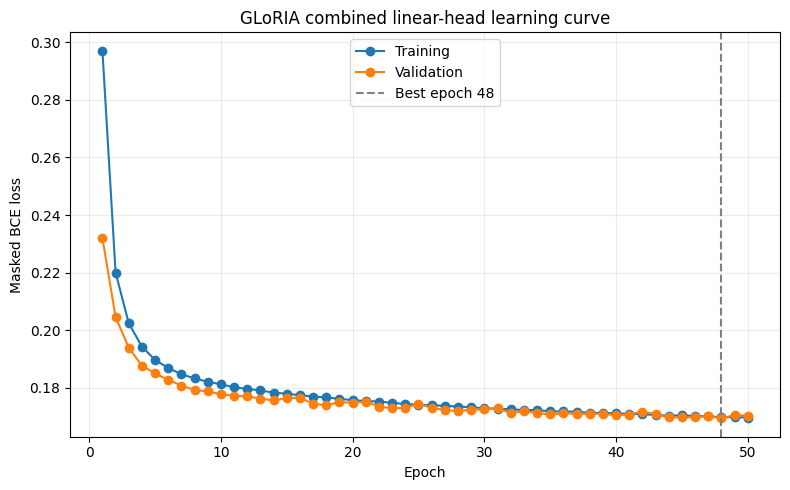

In [9]:
# Plot training and validation loss by epoch
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training')
ax.plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation')
ax.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch {best_epoch}')
ax.set(title='GLoRIA combined linear-head learning curve', xlabel='Epoch', ylabel='Masked BCE loss')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'learning_curve.png', dpi=180)
plt.show()
plt.close(fig)


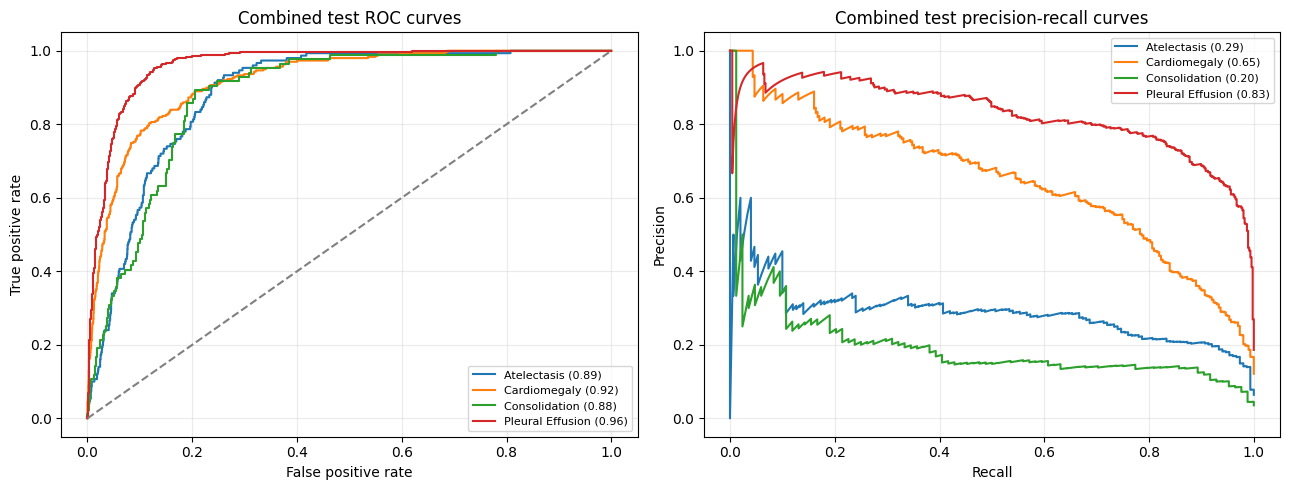

In [10]:
# Plot combined-test ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for index, label in enumerate(LABELS):
    observed = test_mask[:, index].astype(bool)
    truth = test_y[observed, index].astype(int)
    probability = test_probs[observed, index]
    if np.unique(truth).size != 2:
        continue
    fpr, tpr, _ = roc_curve(truth, probability)
    precision, recall, _ = precision_recall_curve(truth, probability)
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics[label]["AUROC"]:.2f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics[label]["AUPRC"]:.2f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Combined test ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Combined test precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'test_roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


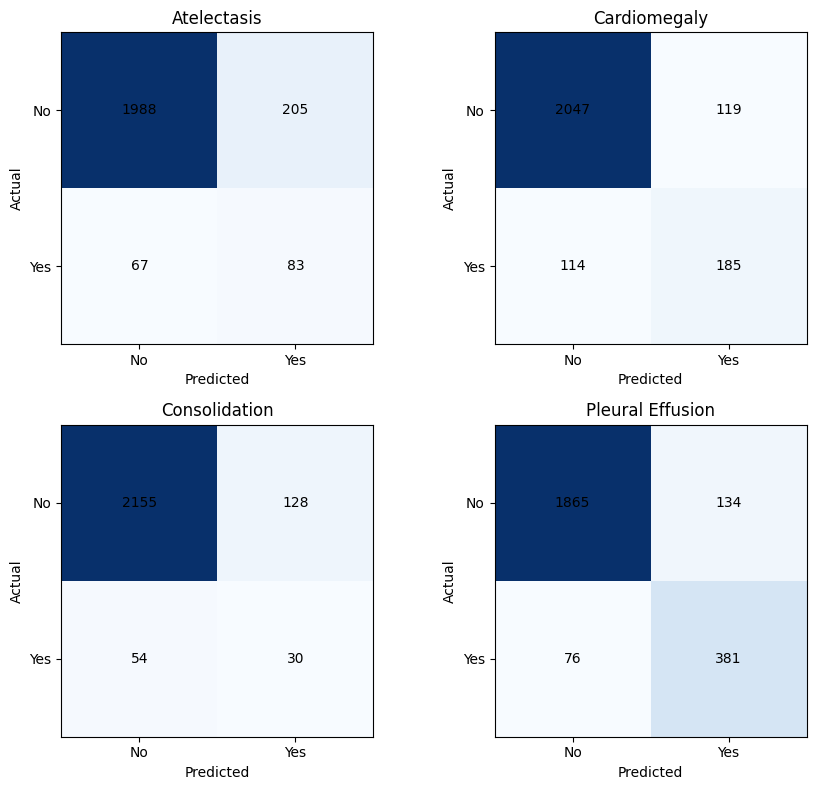

In [11]:
# Plot combined-test confusion matrices at validation-selected thresholds
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for index, label in enumerate(LABELS):
    ax = axes.flat[index]
    observed = test_mask[:, index].astype(bool)
    truth = test_y[observed, index].astype(int)
    predicted = (test_probs[observed, index] >= thresholds[label]).astype(int)
    matrix = confusion_matrix(truth, predicted, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center')
    ax.set(title=label, xlabel='Predicted', ylabel='Actual',
           xticks=[0, 1], yticks=[0, 1], xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
fig.tight_layout()
fig.savefig(RESULTS / 'test_confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [12]:
# Save the combined results, split manifests, and measured run times
history_df.to_csv(RESULTS / 'history.csv', index=False)
metrics_df.to_csv(RESULTS / 'test_metrics.csv')
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
for name, frame in splits.items():
    frame[['sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS]].to_csv(
        RESULTS / f'{name}_split.csv', index=False,
    )

summary = {
    'model': 'GLoRIA released frozen image encoder with a trained four-output linear head',
    'dataset': 'combined CheXpert and VinDr-CXR, four shared findings',
    'archive': str(archive_path),
    'checkpoint': str(checkpoint_path),
    'repository_commit': repo_commit,
    'seed': SEED,
    'max_epochs': MAX_EPOCHS,
    'early_stopping_patience': PATIENCE,
    'best_epoch': best_epoch,
    'image_batch_size': IMAGE_BATCH_SIZE,
    'head_batch_size': HEAD_BATCH_SIZE,
    'optimizer': 'Adam',
    'learning_rate': 1e-4,
    'weight_decay': 1e-6,
    'loss': 'masked BCEWithLogitsLoss',
    'threshold_selection': 'maximum F1 on observed validation labels',
    'feature_extraction_minutes': feature_minutes,
    'head_training_minutes': training_minutes,
    'test_evaluation_seconds': test_seconds,
    'total_run_minutes': (time.perf_counter() - run_start) / 60,
    'split_counts': {name: len(frame) for name, frame in splits.items()},
}
(RESULTS / 'run_info.json').write_text(json.dumps(summary, indent=2))
print(f'Feature extraction: {feature_minutes:.1f} min')
print(f'Head training: {training_minutes:.1f} min')
print(f'Total run: {summary["total_run_minutes"]:.1f} min')
print('Saved files to:', RESULTS)


Feature extraction: 1.1 min
Head training: 0.6 min
Total run: 4.1 min
Saved files to: /kaggle/working/gloria_combined_chexpert_vindr_results
